In [1]:

%pip install osmnx


   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.1 MB 291.3 kB/s eta 0:00:06
   --------- ------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:

import osmnx as ox
import pandas as pd
import matplotlib.pyplot as plt

print("OSMnx version:", ox.__version__)
print("Libraries imported successfully!")


OSMnx version: 2.1.1
Libraries imported successfully!


In [5]:


import osmnx as ox
import matplotlib.pyplot as plt

place = "Gandhinagar, Gujarat, India"

G = ox.graph_from_place(
    place,
    network_type="drive"
)

print("Gandhinagar road network downloaded successfully!")
print("Number of intersections:", len(G.nodes))
print("Number of road segments:", len(G.edges))



Gandhinagar road network downloaded successfully!
Number of intersections: 9895
Number of road segments: 26522


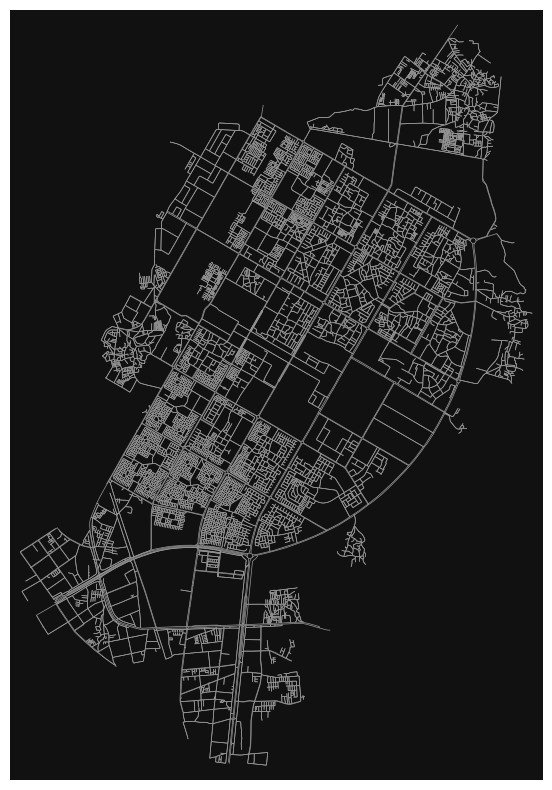

In [6]:

fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.5,
    figsize=(10, 10)
)

plt.show()


In [7]:

import os

os.makedirs("../output", exist_ok=True)

fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.5,
    figsize=(10, 10),
    show=False,
    close=False
)

fig.savefig(
    "../output/gandhinagar_road_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("Road map saved successfully!")


Road map saved successfully!


In [9]:

# Check the road network information

import networkx as nx
import osmnx as ox

print("Is the graph directed?", G.is_directed())
print("Is the graph connected?", nx.is_weakly_connected(G))
print("Total intersections:", len(G.nodes))
print("Total road segments:", len(G.edges))

# Convert intersections into a table
nodes = ox.graph_to_gdfs(G, edges=False)

print("\nFirst 5 intersections:")
print(nodes[["y", "x"]].head())


Is the graph directed? True
Is the graph connected? True
Total intersections: 9895
Total road segments: 26522

First 5 intersections:
                   y          x
osmid                          
323134668  23.196425  72.623720
323138608  23.262078  72.664151
323138717  23.241165  72.656544
323138735  23.241232  72.656421
323138830  23.228924  72.648899


In [10]:

edges = ox.graph_to_gdfs(G, nodes=False)

print("Road network data:")
print(edges.head())

print("\nRoad network columns:")
print(edges.columns.tolist())


Road network data:
                                                      osmid     highway  \
u         v           key                                                 
323134668 11135043514 0                          1200946266  trunk_link   
          11135043524 0    [29384600, 379868490, 379871398]       trunk   
323138608 3459622223  0                           338817490    tertiary   
          8392604337  0                            29377409    tertiary   
          8387086492  0                           338817490    tertiary   

                           oneway reversed       length    ref bridge  \
u         v           key                                               
323134668 11135043514 0     False    False    17.887981    NaN    NaN   
          11135043524 0      True    False  1537.949381  NH147    yes   
323138608 3459622223  0     False     True    11.959121    NaN    NaN   
          8392604337  0      True    False   293.592847    NaN    NaN   
          8387086

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert road length from metres to kilometres
edges["length_km"] = edges["length"] / 1000

print("Total road network length (km):", round(edges["length_km"].sum(), 2))
print("Average road segment length (metres):", round(edges["length"].mean(), 2))
print("Shortest road segment (metres):", round(edges["length"].min(), 2))
print("Longest road segment (metres):", round(edges["length"].max(), 2))


Total road network length (km): 1579.75
Average road segment length (metres): 59.56
Shortest road segment (metres): 0.93
Longest road segment (metres): 1537.95


Road types in Gandhinagar:
highway
residential       23827
tertiary           1939
secondary           305
unclassified        158
primary             157
trunk                81
tertiary_link        29
primary_link         14
trunk_link           10
secondary_link        7
Name: count, dtype: int64


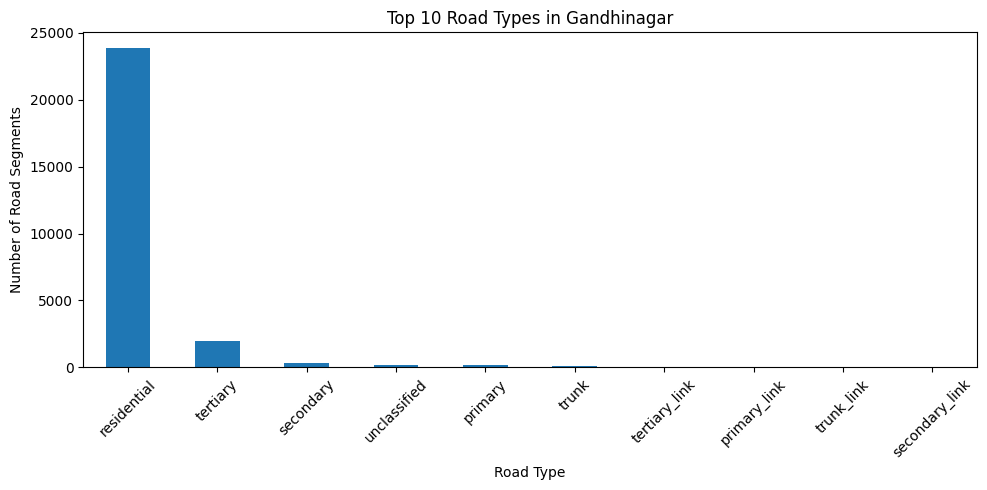

In [12]:

# Count different types of roads
road_types = edges["highway"].explode().value_counts()

print("Road types in Gandhinagar:")
print(road_types)

# Plot the 10 most common road types
road_types.head(10).plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Road Types in Gandhinagar")
plt.xlabel("Road Type")
plt.ylabel("Number of Road Segments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

# Check whether speed and travel time are available

print("Is speed data available?", "speed_kph" in edges.columns)
print("Is travel time available?", "travel_time" in edges.columns)

print("\nSpeed-related columns:")
print([col for col in edges.columns if "speed" in col.lower()])

print("\nTravel-time-related columns:")
print([col for col in edges.columns if "travel_time" in col.lower()])


Is speed data available? False
Is travel time available? False

Speed-related columns:
['maxspeed']

Travel-time-related columns:
[]


In [14]:

# Check the maxspeed values available in the road data

print("Maximum speed values found:")
print(edges["maxspeed"].value_counts().head(15))

print("\nMissing maxspeed values:")
print(edges["maxspeed"].isna().sum())

print("\nTotal road segments:")
print(len(edges))


Maximum speed values found:
maxspeed
40    14
20    12
30    10
60     5
70     4
Name: count, dtype: int64

Missing maxspeed values:
26477

Total road segments:
26522


In [15]:

import pandas as pd
import numpy as np

# Convert maxspeed values into numeric speeds
def get_speed(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, list):
        value = value[0]

    try:
        if isinstance(value, str):
            value = value.split(";")[0].strip()
            value = value.replace("km/h", "").strip()
            value = value.replace("mph", "").strip()

        return float(value)
    except (ValueError, TypeError):
        return np.nan

edges["speed_kph"] = edges["maxspeed"].apply(get_speed)

# Use an assumed speed of 30 km/h where speed is missing
edges["speed_kph"] = edges["speed_kph"].fillna(30)

# Calculate estimated travel time in minutes
edges["travel_time_min"] = (
    edges["length"] / 1000
) / edges["speed_kph"] * 60

print("Speed and travel time calculated!")
print("\nAverage assumed/available speed (km/h):",
      round(edges["speed_kph"].mean(), 2))

print("Total estimated road-segment travel time (minutes):",
      round(edges["travel_time_min"].sum(), 2))

print("\nFirst 5 rows:")
print(edges[["length", "maxspeed", "speed_kph",
             "travel_time_min"]].head())


Speed and travel time calculated!

Average assumed/available speed (km/h): 30.01
Total estimated road-segment travel time (minutes): 3158.25

First 5 rows:
                                length maxspeed  speed_kph  travel_time_min
u         v           key                                                  
323134668 11135043514 0      17.887981      NaN       30.0         0.035776
          11135043524 0    1537.949381      NaN       30.0         3.075899
323138608 3459622223  0      11.959121      NaN       30.0         0.023918
          8392604337  0     293.592847      NaN       30.0         0.587186
          8387086492  0     154.465049      NaN       30.0         0.308930


In [16]:

# Add estimated speed and travel time to the road network

G = ox.add_edge_speeds(G)
G = ox.add_edge_travel_times(G)

print("Speed and travel time added to the graph!")

print("\nSample road information:")

for u, v, key, data in list(G.edges(keys=True, data=True))[:5]:
    print(
        "Road length:", round(data["length"], 2), "metres",
        "| Speed:", round(data["speed_kph"], 2), "km/h",
        "| Travel time:", round(data["travel_time"], 2), "seconds"
    )


Speed and travel time added to the graph!

Sample road information:
Road length: 17.89 metres | Speed: 35.44 km/h | Travel time: 1.82 seconds
Road length: 1537.95 metres | Speed: 35.44 km/h | Travel time: 156.23 seconds
Road length: 11.96 metres | Speed: 46.32 km/h | Travel time: 0.93 seconds
Road length: 293.59 metres | Speed: 46.32 km/h | Travel time: 22.82 seconds
Road length: 154.47 metres | Speed: 46.32 km/h | Travel time: 12.01 seconds


In [17]:

# Select sample starting point and destination

start_location = (23.2156, 72.6369)
end_location = (23.1880, 72.6280)

# Find the nearest road-network nodes
start_node = ox.distance.nearest_nodes(
    G, X=start_location[1], Y=start_location[0]
)

end_node = ox.distance.nearest_nodes(
    G, X=end_location[1], Y=end_location[0]
)

print("Start node:", start_node)
print("Destination node:", end_node)


Start node: 3904527764
Destination node: 3832152244


In [18]:


import networkx as nx

# Route with the shortest road distance
shortest_route = nx.shortest_path(
    G,
    source=start_node,
    target=end_node,
    weight="length"
)

# Route with the lowest estimated travel time
fastest_route = nx.shortest_path(
    G,
    source=start_node,
    target=end_node,
    weight="travel_time"
)

print("Shortest route nodes:", len(shortest_route))
print("Fastest route nodes:", len(fastest_route))

print("Shortest route distance (km):",
      round(nx.path_weight(G, shortest_route, weight="length") / 1000, 2))

print("Fastest route estimated time (minutes):",
      round(nx.path_weight(G, fastest_route, weight="travel_time") / 60, 2))


Shortest route nodes: 38
Fastest route nodes: 31
Shortest route distance (km): 3.36
Fastest route estimated time (minutes): 5.72


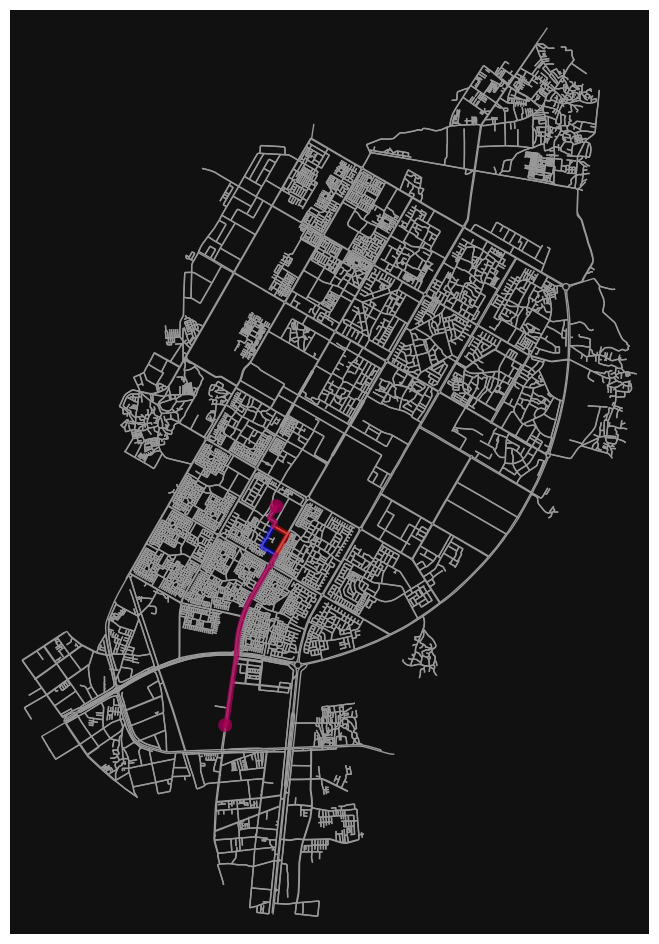

In [19]:

fig, ax = ox.plot_graph_routes(
    G,
    routes=[shortest_route, fastest_route],
    route_colors=["blue", "red"],
    route_linewidth=4,
    node_size=0,
    figsize=(12, 12)
)

plt.show()


In [20]:

import networkx as nx
import pandas as pd

# Calculate distance and travel time for a route
def calculate_route_metrics(route, graph):
    distance_km = nx.path_weight(
        graph, route, weight="length"
    ) / 1000

    time_min = nx.path_weight(
        graph, route, weight="travel_time"
    ) / 60

    return distance_km, time_min


# Calculate shortest and fastest route metrics
shortest_distance, shortest_time = calculate_route_metrics(
    shortest_route, G
)

fastest_distance, fastest_time = calculate_route_metrics(
    fastest_route, G
)

# Create a comparison table
comparison = pd.DataFrame({
    "Route": ["Shortest Route", "Fastest Route"],
    "Distance (km)": [shortest_distance, fastest_distance],
    "Estimated Time (minutes)": [shortest_time, fastest_time]
})

comparison = comparison.round(2)

print(comparison)


            Route  Distance (km)  Estimated Time (minutes)
0  Shortest Route           3.36                      6.46
1   Fastest Route           3.37                      5.72


In [21]:

import pandas as pd

vehicle_df = pd.read_csv("../data/vehicle_emission.csv")

print("Vehicle dataset loaded successfully!")
print("Dataset shape:", vehicle_df.shape)

print("\nAvailable columns:")
print(vehicle_df.columns.tolist())

print("\nCO2 emissions summary:")
print(vehicle_df["CO2 emissions (g/km)"].describe())


Vehicle dataset loaded successfully!
Dataset shape: (10060, 15)

Available columns:
['Model year', 'Make', 'Model', 'Vehicle class', 'Engine size (L)', 'Cylinders', 'Transmission', 'Fuel type', 'City (L/100 km)', 'Highway (L/100 km)', 'Combined (L/100 km)', 'Combined (mpg)', 'CO2 emissions (g/km)', 'CO2 rating', 'Smog rating']

CO2 emissions summary:
count    10060.000000
mean       253.711332
std         60.474917
min         94.000000
25%        210.000000
50%        250.000000
75%        292.000000
max        608.000000
Name: CO2 emissions (g/km), dtype: float64


In [22]:

# Average CO2 emission rate from the vehicle dataset
average_co2_g_per_km = vehicle_df[
    "CO2 emissions (g/km)"
].mean()

# Estimate emissions for the two routes
comparison["Estimated CO2 (grams)"] = (
    comparison["Distance (km)"] * average_co2_g_per_km
)

comparison["Estimated CO2 (kg)"] = (
    comparison["Estimated CO2 (grams)"] / 1000
)

comparison = comparison.round(2)

print("Route comparison with estimated CO2 emissions:")
print(comparison)


Route comparison with estimated CO2 emissions:
            Route  Distance (km)  Estimated Time (minutes)  \
0  Shortest Route           3.36                      6.46   
1   Fastest Route           3.37                      5.72   

   Estimated CO2 (grams)  Estimated CO2 (kg)  
0                 852.47                0.85  
1                 855.01                0.86  


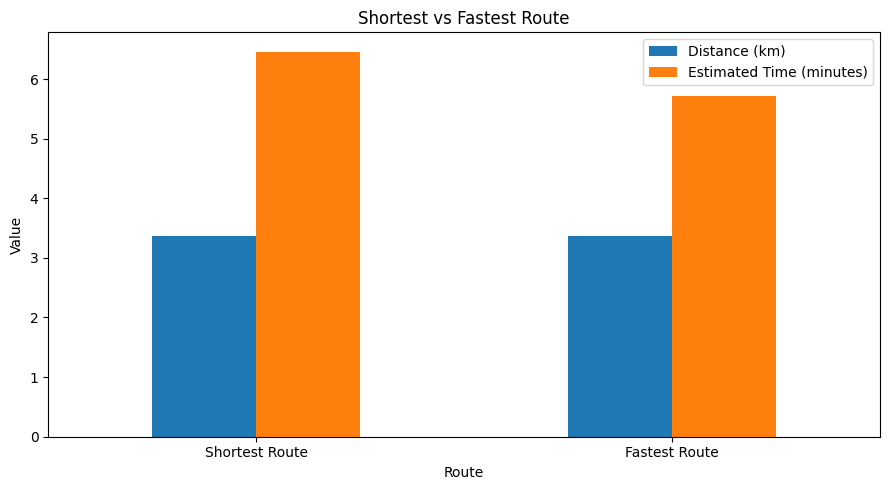

In [23]:

import matplotlib.pyplot as plt

comparison.plot(
    x="Route",
    y=["Distance (km)", "Estimated Time (minutes)"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Shortest vs Fastest Route")
plt.ylabel("Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [24]:

# Check whether elevation data is already available

print("Elevation data available:", "elevation" in G.nodes[list(G.nodes)[0]])

print("\nNode attributes:")
print(list(G.nodes[list(G.nodes)[0]].keys()))

print("\nRoad attributes:")
first_edge = list(G.edges(data=True))[0]
print(list(first_edge[2].keys()))


Elevation data available: False

Node attributes:
['y', 'x', 'street_count']

Road attributes:
['osmid', 'highway', 'oneway', 'reversed', 'length', 'speed_kph', 'travel_time']


In [25]:

%pip install rasterio


   ---------------------------------------- 0.0/31.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.5 MB ? eta -:--:--
    --------------------------------------- 0.5/31.5 MB 350.1 kB/s eta 0:01:29
    --------------------------------------- 0.5/31.5 MB 350.1 kB/s eta 0:01:29
    --------------------------------------- 0.8/31.5 MB 462.3 kB/s eta 0:01:07
   - -------------------------------------- 1.0/31.5 MB 562.7 kB/s eta 0:00:55
   - -------------------------------------- 1.0/31.5 MB 562.7 kB/s eta 0:00:55
   - -------------------------------------- 1.3/31.5 MB 592.2 kB/s eta 0:00:51
   - -------------------------------------- 1.3/31.5 MB 592.2 kB/s eta 0:00:51
   - ----------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:

import rasterio

print("Rasterio version:", rasterio.__version__)
print("Elevation data processing package is ready!")


Rasterio version: 1.5.2
Elevation data processing package is ready!


In [27]:

import importlib.util

print(
    "Py3dep available:",
    importlib.util.find_spec("py3dep") is not None
)

print(
    "Rasterio available:",
    importlib.util.find_spec("rasterio") is not None
)


Py3dep available: False
Rasterio available: True


In [28]:

# Get the road intersections as a table
nodes = ox.graph_to_gdfs(G, edges=False)

print("Gandhinagar road network coordinates")

print("Minimum latitude:", nodes["y"].min())
print("Maximum latitude:", nodes["y"].max())

print("Minimum longitude:", nodes["x"].min())
print("Maximum longitude:", nodes["x"].max())


Gandhinagar road network coordinates
Minimum latitude: 23.1651544
Maximum latitude: 23.2740437
Minimum longitude: 72.6029336
Maximum longitude: 72.6848387


In [29]:

import rasterio
import os

elevation_folder = "../data/elevation"

print("Elevation folder exists:", os.path.exists(elevation_folder))

print("Files in elevation folder:")
print(os.listdir(elevation_folder))


Elevation folder exists: True
Files in elevation folder:
['n23_e072_1arc_v3.tif']


In [30]:

import os
import rasterio

elevation_folder = "../data/elevation"

tif_files = [
    f for f in os.listdir(elevation_folder)
    if f.lower().endswith(".tif")
]

print("TIF files found:", tif_files)

if len(tif_files) > 0:
    tif_path = os.path.join(elevation_folder, tif_files[0])

    with rasterio.open(tif_path) as src:
        print("File opened successfully!")
        print("Coordinate system:", src.crs)
        print("Image dimensions:", src.width, "x", src.height)
        print("Elevation bounds:", src.bounds)
        print("No-data value:", src.nodata)
else:
    print("No .tif file found. Check the file extension.")


TIF files found: ['n23_e072_1arc_v3.tif']
File opened successfully!
Coordinate system: EPSG:4326
Image dimensions: 3601 x 3601
Elevation bounds: BoundingBox(left=71.99986111111112, bottom=22.999861111111112, right=73.0001388888889, top=24.00013888888889)
No-data value: -32767.0


Elevation data loaded!
Raster size: (3601, 3601)
Coordinate system: EPSG:4326
Minimum elevation: 12.0
Maximum elevation: 479.0
Mean elevation: 94.07


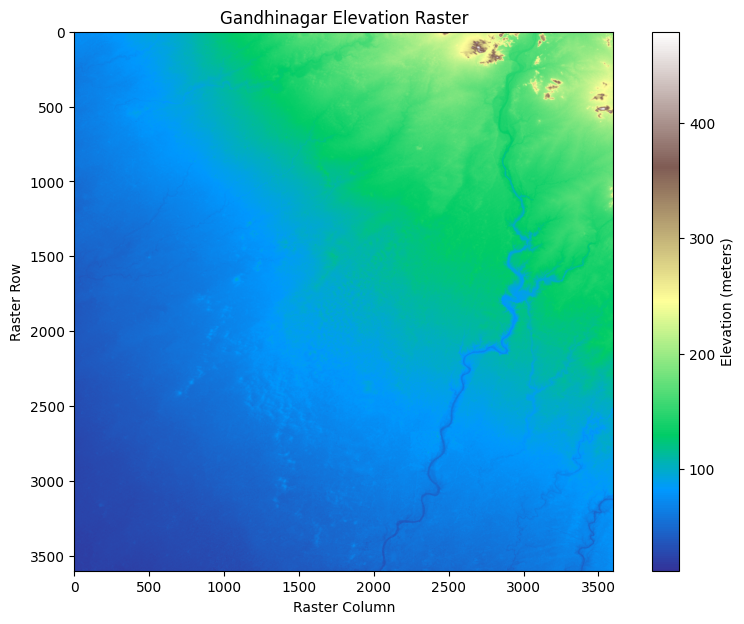

In [31]:

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt

elevation_folder = "../data/elevation"

tif_files = [
    f for f in os.listdir(elevation_folder)
    if f.lower().endswith(".tif")
]

tif_path = os.path.join(elevation_folder, tif_files[0])

with rasterio.open(tif_path) as src:
    elevation = src.read(1, masked=True)

    print("Elevation data loaded!")
    print("Raster size:", elevation.shape)
    print("Coordinate system:", src.crs)

    valid_elevation = elevation.compressed()

    if len(valid_elevation) > 0:
        print("Minimum elevation:", round(float(valid_elevation.min()), 2))
        print("Maximum elevation:", round(float(valid_elevation.max()), 2))
        print("Mean elevation:", round(float(valid_elevation.mean()), 2))

plt.figure(figsize=(10, 7))
plt.imshow(elevation, cmap="terrain")
plt.colorbar(label="Elevation (meters)")
plt.title("Gandhinagar Elevation Raster")
plt.xlabel("Raster Column")
plt.ylabel("Raster Row")
plt.show()


In [32]:

import os
import numpy as np
import rasterio
import pandas as pd

elevation_folder = "../data/elevation"

tif_files = [
    f for f in os.listdir(elevation_folder)
    if f.lower().endswith(".tif")
]

tif_path = os.path.join(elevation_folder, tif_files[0])

with rasterio.open(tif_path) as src:
    # Road network ke intersection coordinates
    nodes = ox.graph_to_gdfs(G, edges=False)

    # Raster ko longitude-latitude coordinates mein elevation ke liye sample karo
    coordinates = list(zip(nodes["x"], nodes["y"]))
    sampled_values = list(src.sample(coordinates, masked=True))

    elevations = []
    for value in sampled_values:
        if np.ma.is_masked(value[0]):
            elevations.append(np.nan)
        else:
            elevations.append(float(value[0]))

    nodes["elevation_m"] = elevations

print("Total intersections:", len(nodes))
print("Intersections with elevation:", nodes["elevation_m"].notna().sum())
print("Intersections without elevation:", nodes["elevation_m"].isna().sum())

print("\nSample elevation values:")
print(nodes[["y", "x", "elevation_m"]].head(10))

print("\nElevation summary:")
print(nodes["elevation_m"].describe())


Total intersections: 9895
Intersections with elevation: 9895
Intersections without elevation: 0

Sample elevation values:
                   y          x  elevation_m
osmid                                       
323134668  23.196425  72.623720         78.0
323138608  23.262078  72.664151         83.0
323138717  23.241165  72.656544         80.0
323138735  23.241232  72.656421         78.0
323138830  23.228924  72.648899         78.0
323138910  23.233329  72.675677         79.0
323139090  23.238086  72.662747         83.0
323139329  23.256808  72.626856         83.0
323139597  23.197815  72.631314         75.0
323139603  23.205894  72.634353         76.0

Elevation summary:
count    9895.000000
mean       77.500354
std         4.578270
min        59.000000
25%        74.000000
50%        78.000000
75%        81.000000
max        95.000000
Name: elevation_m, dtype: float64


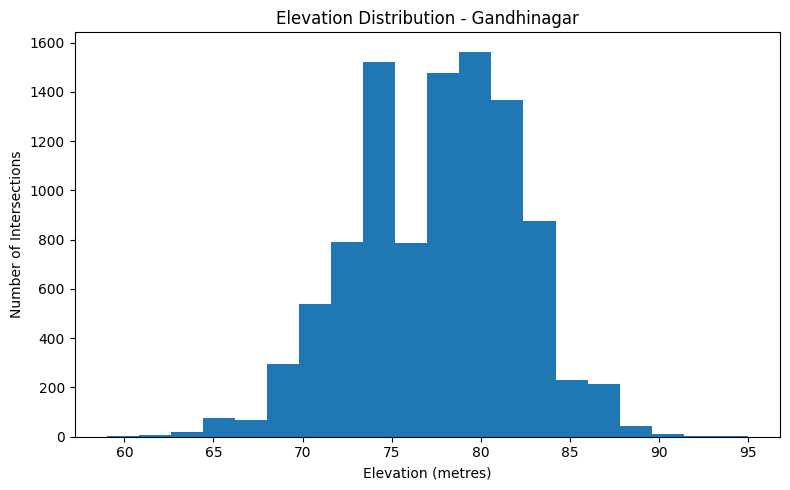

In [33]:
import matplotlib.pyplot as plt

# Plot elevation distribution
plt.figure(figsize=(8, 5))

plt.hist(nodes["elevation_m"], bins=20)

plt.title("Elevation Distribution - Gandhinagar")
plt.xlabel("Elevation (metres)")
plt.ylabel("Number of Intersections")

plt.tight_layout()
plt.show()

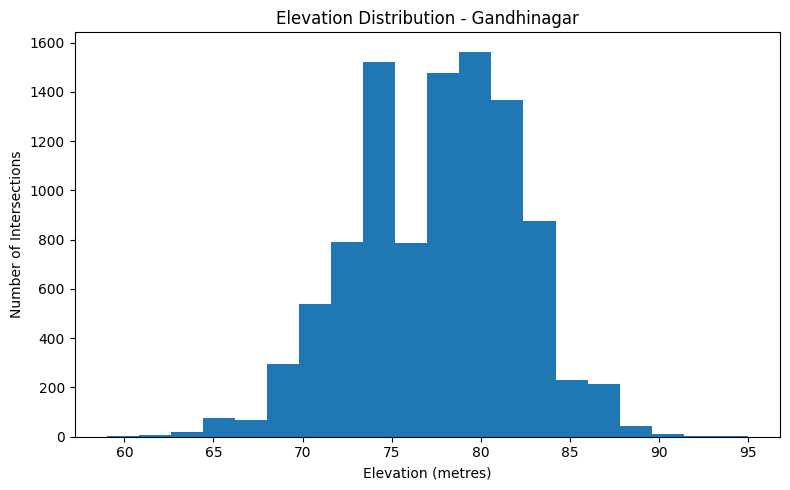

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(nodes["elevation_m"], bins=20)

plt.title("Elevation Distribution - Gandhinagar")
plt.xlabel("Elevation (metres)")
plt.ylabel("Number of Intersections")

plt.tight_layout()
plt.savefig("../output/elevation_distribution.png", dpi=300)
plt.show()


In [36]:

print("Node columns:")
print(nodes.columns.tolist())

print("\nGraph node attributes:")
first_node = list(G.nodes)[0]
print(G.nodes[first_node])

print("\nElevation column in graph:",
      "elevation_m" in G.nodes[first_node])


Node columns:
['y', 'x', 'street_count', 'highway', 'geometry']

Graph node attributes:
{'y': 23.1964254, 'x': 72.62372, 'street_count': 3}

Elevation column in graph: False


In [37]:

import os

elevation_folder = "../data/elevation"

print("Files in elevation folder:")
print(os.listdir(elevation_folder))


Files in elevation folder:
['n23_e072_1arc_v3.tif']


In [38]:

import rasterio
import numpy as np
import osmnx as ox

# Open the downloaded elevation raster
elevation_path = "../data/elevation/n23_e072_1arc_v3.tif"

with rasterio.open(elevation_path) as src:
    print("Raster CRS:", src.crs)
    print("Raster size:", src.width, "x", src.height)

    # Get coordinates of all road intersections
    node_ids = list(G.nodes)
    xs = [G.nodes[node]["x"] for node in node_ids]
    ys = [G.nodes[node]["y"] for node in node_ids]

    # Read elevation at each intersection
    coordinates = list(zip(xs, ys))
    sampled_values = list(src.sample(coordinates))

    elevations = []
    for value in sampled_values:
        height = value[0]

        if src.nodata is not None and height == src.nodata:
            elevations.append(np.nan)
        else:
            elevations.append(float(height))

# Add elevation to the graph nodes
for node_id, height in zip(node_ids, elevations):
    G.nodes[node_id]["elevation_m"] = height

# Create updated node and edge tables
nodes, edges = ox.graph_to_gdfs(G)

print("\nTotal intersections:", len(nodes))
print("Intersections with elevation:",
      nodes["elevation_m"].notna().sum())
print("Intersections without elevation:",
      nodes["elevation_m"].isna().sum())

print("\nElevation summary:")
print(nodes["elevation_m"].describe())


Raster CRS: EPSG:4326
Raster size: 3601 x 3601

Total intersections: 9895
Intersections with elevation: 9895
Intersections without elevation: 0

Elevation summary:
count    9895.000000
mean       77.500354
std         4.578270
min        59.000000
25%        74.000000
50%        78.000000
75%        81.000000
max        95.000000
Name: elevation_m, dtype: float64


In [39]:

# Look up elevation at the beginning and end of each road
elevation_lookup = nodes["elevation_m"].to_dict()

edges["start_elevation_m"] = (
    edges.index.get_level_values("u").map(elevation_lookup)
)

edges["end_elevation_m"] = (
    edges.index.get_level_values("v").map(elevation_lookup)
)

edges["elevation_change_m"] = (
    edges["end_elevation_m"] - edges["start_elevation_m"]
)

edges["absolute_elevation_change_m"] = (
    edges["elevation_change_m"].abs()
)

# Calculate slope only when elevation and length are valid
edges["slope_percent"] = np.where(
    edges["length"] > 0,
    edges["elevation_change_m"] / edges["length"] * 100,
    np.nan
)

display(
    edges[
        [
            "length",
            "start_elevation_m",
            "end_elevation_m",
            "elevation_change_m",
            "slope_percent"
        ]
    ].head(10)
)


length  start_elevation_m  end_elevation_m  \
u         v           key                                                    
323134668 11135043514 0      17.887981               78.0             78.0   
          11135043524 0    1537.949381               78.0             78.0   
323138608 3459622223  0      11.959121               83.0             82.0   
          8392604337  0     293.592847               83.0             85.0   
          8387086492  0     154.465049               83.0             81.0   
323138717 8389155037  0     109.723663               80.0             80.0   
          323138735   0      14.789514               80.0             78.0   
323138735 3900987833  0      24.953844               78.0             81.0   
323138830 8398960441  0      12.858477               78.0             78.0   
          11729760755 0      67.983102               78.0             79.0   

                           elevation_change_m  slope_percent  
u         v           key                                     
323134668 11135043514 0                   0.0       0.000000  
          11135043524 0                   0.0       0.000000  
323138608 3459622223  0                  -1.0      -8.361819  
          8392604337  0                   2.0       0.681216  
          8387086492  0                  -2.0      -1.294791  
323138717 8389155037  0                   0.0       0.000000  
          323138735   0                  -2.0     -13.523095  
323138735 3900987833  0                   3.0      12.022196  
323138830 8398960441  0                   0.0       0.000000  
          11729760755 0                   1.0       1.470954

In [40]:

# Check elevation and slope information

print("Total road segments:", len(edges))

print("\nElevation change summary:")
print(edges["elevation_change_m"].describe())

print("\nSlope percentage summary:")
print(edges["slope_percent"].describe())

print("\nRoad segments with uphill slope:",
      (edges["slope_percent"] > 0).sum())

print("Road segments with downhill slope:",
      (edges["slope_percent"] < 0).sum())

print("Road segments with zero slope:",
      (edges["slope_percent"] == 0).sum())


Total road segments: 26522

Elevation change summary:
count    26522.000000
mean        -0.000528
std          1.986930
min        -15.000000
25%         -1.000000
50%          0.000000
75%          1.000000
max         15.000000
Name: elevation_change_m, dtype: float64

Slope percentage summary:
count    26522.000000
mean         0.001553
std          5.155596
min        -66.714163
25%         -2.051293
50%          0.000000
75%          2.067416
max         66.714163
Name: slope_percent, dtype: float64

Road segments with uphill slope: 8865
Road segments with downhill slope: 8868
Road segments with zero slope: 8789


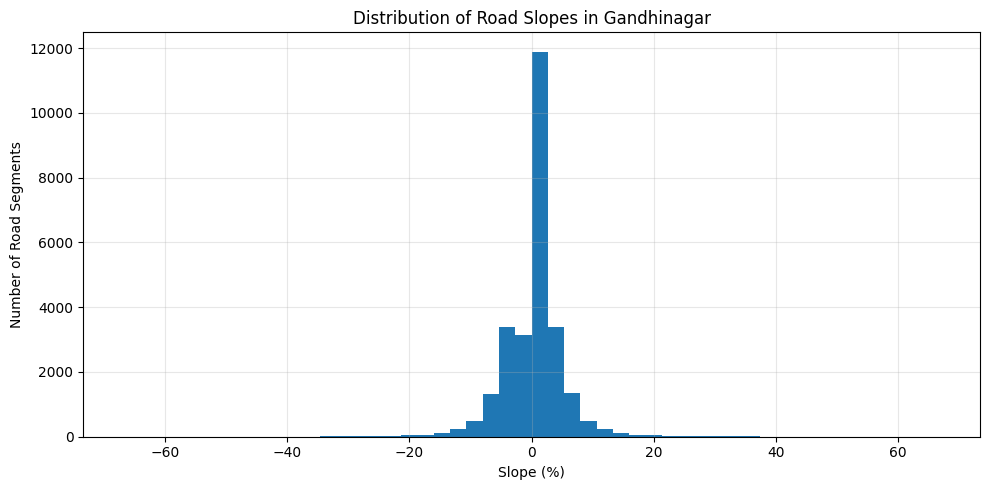

In [41]:

import matplotlib.pyplot as plt

# Plot the distribution of road slopes
plt.figure(figsize=(10, 5))

plt.hist(
    edges["slope_percent"].dropna(),
    bins=50
)

plt.title("Distribution of Road Slopes in Gandhinagar")
plt.xlabel("Slope (%)")
plt.ylabel("Number of Road Segments")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


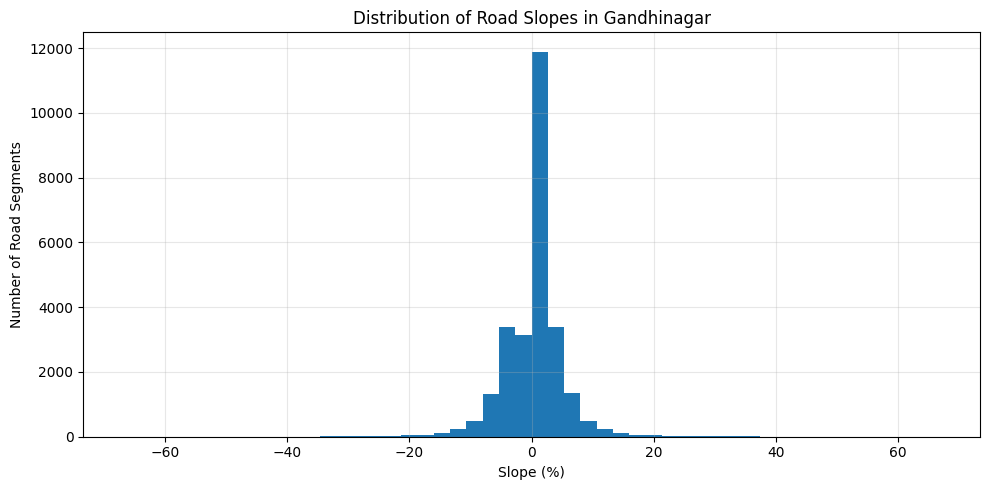

Slope distribution graph saved successfully!


In [42]:

import os

output_folder = "../output"
os.makedirs(output_folder, exist_ok=True)

plt.figure(figsize=(10, 5))
plt.hist(edges["slope_percent"].dropna(), bins=50)

plt.title("Distribution of Road Slopes in Gandhinagar")
plt.xlabel("Slope (%)")
plt.ylabel("Number of Road Segments")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(output_folder, "slope_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Slope distribution graph saved successfully!")


In [43]:

# Check roads with unusually high slope values

print("Roads with slope above 20%:",
      (edges["slope_percent"] > 20).sum())

print("Roads with slope below -20%:",
      (edges["slope_percent"] < -20).sum())

print("\nHighest positive slopes:")
print(
    edges.loc[
        edges["slope_percent"] > 20,
        ["length", "elevation_change_m", "slope_percent"]
    ].head(10)
)

print("\nLowest negative slopes:")
print(
    edges.loc[
        edges["slope_percent"] < -20,
        ["length", "elevation_change_m", "slope_percent"]
    ].head(10)
)


Roads with slope above 20%: 124
Roads with slope below -20%: 128

Highest positive slopes:
                              length  elevation_change_m  slope_percent
u         v           key                                              
323141834 323141835   0    13.888539                 3.0      21.600544
323141836 323141837   0     8.085845                 3.0      37.101874
441123067 3832404611  0    14.097910                 3.0      21.279750
441123094 441123328   0     7.730453                 3.0      38.807556
441130231 3832356555  0     3.463101                 1.0      28.875854
780261196 441123128   0    11.136649                 3.0      26.938085
780264115 780267250   0    11.581726                 3.0      25.902876
780264482 3455640019  0    67.935822                15.0      22.079662
780264709 780264874   0    14.966248                 4.0      26.726805
780267018 12647268534 0     7.503931                 2.0      26.652697

Lowest negative slopes:
                    

In [44]:

# Check extreme slope values

print("Total road segments:", len(edges))

print("Slope above 20%:",
      (edges["slope_percent"] > 20).sum())

print("Slope below -20%:",
      (edges["slope_percent"] < -20).sum())

print("Missing slope values:",
      edges["slope_percent"].isna().sum())

print("\nRoad segments with the highest slopes:")

print(
    edges.loc[
        edges["slope_percent"].abs().nlargest(10).index,
        ["length", "elevation_change_m", "slope_percent"]
    ]
)


Total road segments: 26522
Slope above 20%: 124
Slope below -20%: 128
Missing slope values: 0

Road segments with the highest slopes:
                                length  elevation_change_m  slope_percent
u           v           key                                              
5424016284  8382899843  0    11.991457                -8.0     -66.714163
8382899843  5424016284  0    11.991457                 8.0      66.714163
8395756213  8395756214  0     7.200342                -4.0     -55.552916
3442782095  3442782096  0     5.503497                -3.0     -54.510797
3442782096  3442782095  0     5.503497                 3.0      54.510797
8386895548  8387395882  0     5.541218                -3.0     -54.139717
8387395882  8386895548  0     5.541218                 3.0      54.139717
3459126326  12647260603 0     5.649157                -3.0     -53.105266
12647260603 3459126326  0     5.649157                 3.0      53.105266
6887993349  11676297622 0     6.017439              

In [46]:

import numpy as np

# Make a separate copy so original road data remains unchanged
edges_route = edges.copy()

# Ensure road length is available in kilometres
edges_route["length_km"] = edges_route["length"] / 1000

# Use absolute slope to identify steep roads
edges_route["slope_abs"] = edges_route["slope_percent"].abs()

# Apply a small penalty to steeper roads
edges_route["slope_penalty"] = (
    1 + np.minimum(edges_route["slope_abs"], 15) / 100
)

# Calculate experimental routing cost
edges_route["eco_cost"] = (
    edges_route["length"] * edges_route["slope_penalty"]
)

print("Experimental routing cost created!")
print(
    edges_route[
        ["length", "slope_percent", "slope_penalty", "eco_cost"]
    ].head(10)
)


Experimental routing cost created!
                                length  slope_percent  slope_penalty  \
u         v           key                                              
323134668 11135043514 0      17.887981       0.000000       1.000000   
          11135043524 0    1537.949381       0.000000       1.000000   
323138608 3459622223  0      11.959121      -8.361819       1.083618   
          8392604337  0     293.592847       0.681216       1.006812   
          8387086492  0     154.465049      -1.294791       1.012948   
323138717 8389155037  0     109.723663       0.000000       1.000000   
          323138735   0      14.789514     -13.523095       1.135231   
323138735 3900987833  0      24.953844      12.022196       1.120222   
323138830 8398960441  0      12.858477       0.000000       1.000000   
          11729760755 0      67.983102       1.470954       1.014710   

                              eco_cost  
u         v           key               
323134668 11135043

In [47]:

import networkx as nx
import osmnx as ox
import pandas as pd
import matplotlib.pyplot as plt

# Create a graph copy for slope-aware routing
G_eco = G.copy()

# Add slope-aware costs from the edge dataframe
for u, v, k, data in G_eco.edges(keys=True, data=True):
    if (u, v, k) in edges_route.index:
        row = edges_route.loc[(u, v, k)]
        data["eco_cost"] = float(row["eco_cost"])
    else:
        data["eco_cost"] = float(data["length"])

print("Eco-routing costs added to the graph!")
print("Nodes:", len(G_eco.nodes))
print("Road segments:", len(G_eco.edges))


Eco-routing costs added to the graph!
Nodes: 9895
Road segments: 26522


In [48]:

# Sample coordinates (latitude, longitude)
start_location = (23.2156, 72.6369)
end_location = (23.1880, 72.6280)

# Find nearest road-network nodes
start_node = ox.distance.nearest_nodes(
    G, X=start_location[1], Y=start_location[0]
)

end_node = ox.distance.nearest_nodes(
    G, X=end_location[1], Y=end_location[0]
)

# Route 1: shortest distance
route_shortest = nx.shortest_path(
    G, start_node, end_node, weight="length"
)

# Route 2: slope-aware experimental cost
route_eco = nx.shortest_path(
    G_eco, start_node, end_node, weight="eco_cost"
)

# Calculate distances
def route_distance_km(graph, route):
    distance = 0
    for u, v in zip(route[:-1], route[1:]):
        edge_data = graph.get_edge_data(u, v)
        shortest_edge = min(
            edge_data.values(),
            key=lambda d: d.get("length", float("inf"))
        )
        distance += shortest_edge["length"]
    return distance / 1000

print("Shortest route distance (km):",
      round(route_distance_km(G, route_shortest), 3))

print("Slope-aware route distance (km):",
      round(route_distance_km(G_eco, route_eco), 3))

print("Shortest route road segments:", len(route_shortest) - 1)
print("Slope-aware route road segments:", len(route_eco) - 1)


Shortest route distance (km): 3.36
Slope-aware route distance (km): 3.372
Shortest route road segments: 37
Slope-aware route road segments: 30


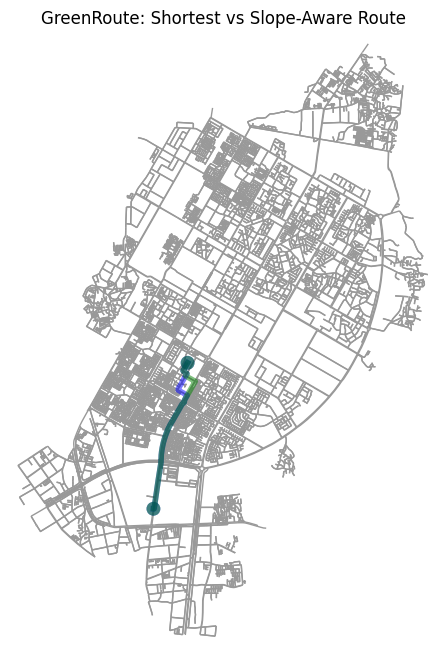

In [49]:

# Plot the shortest route and slope-aware route

fig, ax = ox.plot_graph_routes(
    G,
    routes=[route_shortest, route_eco],
    route_colors=["blue", "green"],
    route_linewidths=[4, 4],
    node_size=0,
    bgcolor="white",
    show=False,
    close=False
)

ax.set_title("GreenRoute: Shortest vs Slope-Aware Route")

plt.show()


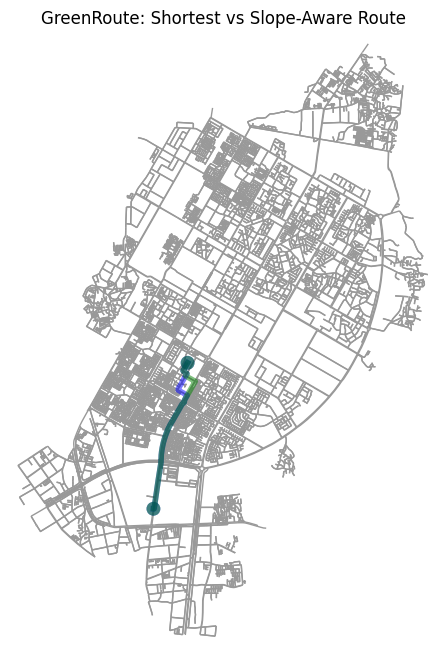

Route comparison map saved successfully!


In [50]:

import os

os.makedirs("../output", exist_ok=True)

fig, ax = ox.plot_graph_routes(
    G,
    routes=[route_shortest, route_eco],
    route_colors=["blue", "green"],
    route_linewidths=[4, 4],
    node_size=0,
    bgcolor="white",
    show=False,
    close=False
)

ax.set_title("GreenRoute: Shortest vs Slope-Aware Route")

fig.savefig(
    "../output/route_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Route comparison map saved successfully!")


In [51]:

import pandas as pd

# Calculate route distances
shortest_distance = route_distance_km(G, route_shortest)
eco_distance = route_distance_km(G_eco, route_eco)

# Baseline emission factor from the vehicle dataset
# This is the dataset-wide average, not a route-specific model
average_co2 = 253.711  # grams per kilometre

# Estimate emissions using distance only
shortest_co2 = shortest_distance * average_co2
eco_co2 = eco_distance * average_co2

# Create a comparison table
route_comparison = pd.DataFrame({
    "Route": ["Shortest Distance", "Slope-Aware Experimental"],
    "Distance (km)": [shortest_distance, eco_distance],
    "Estimated CO2 (g)": [shortest_co2, eco_co2]
})

route_comparison["Distance (km)"] = (
    route_comparison["Distance (km)"].round(3)
)

route_comparison["Estimated CO2 (g)"] = (
    route_comparison["Estimated CO2 (g)"].round(2)
)

display(route_comparison)


,Route,Distance (km),Estimated CO2 (g)
0,Shortest Distance,3.360,852.46
1,Slope-Aware Experimental,3.372,855.49


In [52]:

import os

os.makedirs("../output", exist_ok=True)

route_comparison.to_csv(
    "../output/route_comparison.csv",
    index=False
)

print("Route comparison table saved successfully!")


Route comparison table saved successfully!


In [53]:

import os
import pandas as pd
import numpy as np

# Create output folder if it does not exist
os.makedirs("../output", exist_ok=True)

# 1. Save road network statistics
road_statistics = pd.DataFrame({
    "Metric": [
        "Total intersections",
        "Total road segments",
        "Total road length (km)",
        "Average road length (m)"
    ],
    "Value": [
        len(nodes),
        len(edges),
        edges["length"].sum() / 1000,
        edges["length"].mean()
    ]
})

road_statistics.to_csv(
    "../output/road_network_statistics.csv",
    index=False
)

# 2. Save elevation summary
elevation_summary = nodes["elevation_m"].describe().reset_index()
elevation_summary.columns = ["Statistic", "Elevation (m)"]

elevation_summary.to_csv(
    "../output/elevation_summary.csv",
    index=False
)

# 3. Save road slope summary
slope_summary = edges["slope_percent"].describe().reset_index()
slope_summary.columns = ["Statistic", "Slope (%)"]

slope_summary.to_csv(
    "../output/slope_summary.csv",
    index=False
)

# 4. Check output files
print("Final result files saved successfully!\n")

print("Files in output folder:")
for file in sorted(os.listdir("../output")):
    print("-", file)

print("\nRoad network statistics:")
display(road_statistics)

print("\nElevation summary:")
display(elevation_summary)

print("\nSlope summary:")
display(slope_summary)


Final result files saved successfully!

Files in output folder:
- elevation_distribution.png
- elevation_summary.csv
- gandhinagar_road_map.png
- road_network_statistics.csv
- route_comparison.csv
- route_comparison.png
- slope_distribution.png
- slope_summary.csv

Road network statistics:


,Metric,Value
0,Total intersections,9895.000000
1,Total road segments,26522.000000
2,Total road length (km),1579.745580
3,Average road length (m),59.563592



Elevation summary:


,Statistic,Elevation (m)
0,count,9895.000000
1,mean,77.500354
2,std,4.578270
3,min,59.000000
4,25%,74.000000
5,50%,78.000000
6,75%,81.000000
7,max,95.000000



Slope summary:


,Statistic,Slope (%)
0,count,26522.000000
1,mean,0.001553
2,std,5.155596
3,min,-66.714163
4,25%,-2.051293
5,50%,0.000000
6,75%,2.067416
7,max,66.714163
